# Neural Network

In [98]:
from micrograd.engine import Value

import random

In [99]:
from graphviz import Digraph


def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root, format="svg", rankdir="LR"):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ["LR", "TB"]
    nodes, edges = trace(root)
    dot = Digraph(
        format=format, graph_attr={"rankdir": rankdir}
    )  # , node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(
            name=str(id(n)),
            label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),
            shape="record",
        )
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

### QA
1. what should Neuron return as parameters()?

In [100]:
class Neuron:
    """A neuron is a function o a sequence of inputs, weights and a bias"""

    def __init__(self, nin, label=""):
        """
        nin: int, the number of inputs
        """
        # if label create the prefix with hyphen, empty otherwise. Ex. N-
        self.label = "" if len(label) > 0 else f"{label}-"
        self.w = [
            Value(random.uniform(-1, 1), label=f"{self.label}V{i}") for i in range(nin)
        ]
        self.b = Value(random.uniform(-1, 1), label=f"{label}-b")

    def __call__(self, x):
        """x - input data"""
        act = sum([wi * xi for wi, xi in zip(self.w, x)]) + self.b  # activation
        out = act.tahn()  # normalization
        return out

    def parameters(self):
        return [p for p in self.w]


class Layer:
    """A layer of Neurons.
    nin: number of inputs to a each neuron;
    nout: number of outputs of the layer
    """

    def __init__(self, nin, nout, label=""):
        # if label create the prefix with hyphen, empty otherwise. Ex. L-
        self.label = "" if len(label) > 0 else f"{label}-"
        self.neurons = [Neuron(nin, label=f"{self.label}N{i}") for i in range(nout)]

    def __call__(self, x):
        """x - input data"""
        outs = [n(x) for n in self.neurons]
        out = outs[0] if len(outs) == 1 else outs
        return out

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


class MLP:
    """Multi Layer Perceptron.
    nin - int, number of inputs
    nouts - list of ints, number of inner layers, plus one final layer. Ex.: [4, 1] - 4 inner, 1 out.

    Each inner layer outputs, is the input to the next layer.
    """

    def __init__(self, nin, nouts):
        # if label create the prefix with hyphen, empty otherwise. Ex. M-
        sz = [nin] + nouts
        self.layers = [
            Layer(sz[i], sz[i + 1], label=f"L{i}") for i in range(len(nouts))
        ]

    def __call__(self, x):
        """x - input data"""
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for l in self.layers for p in l.parameters()]

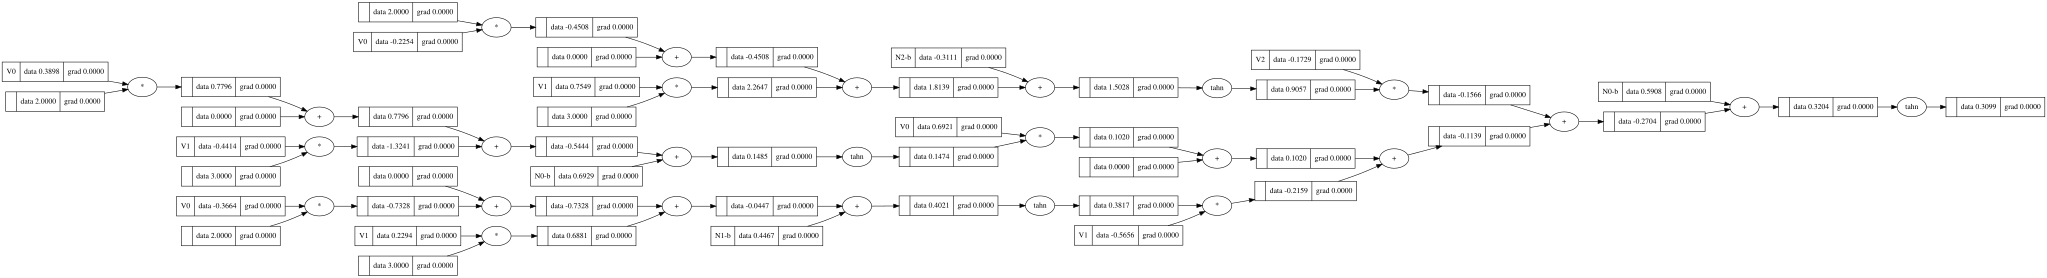

In [101]:
xs = [2.0, 3.0]
# n1 = Neuron(2, label="N1")
# n1 = Layer(2, 3, label="L1")
n1 = MLP(2, [3, 1])
o = n1(xs)
draw_dot(o)

In [102]:
def tests():
    # neuron
    # init
    n = Neuron(0)
    assert n.w == []

    n = Neuron(1)
    assert len(n.w) == 1


tests()